# Periodic lattice displacement mapping
This example notebook demonstrates the fourier masking approach for measuring periodic lattice displacements. An atomic resolution HAADF STEM image of the charge ordered perovskite Nd$_{0.5}$Sr$_{0.5}$MnO$_3$ thin film is used. 

The method used is described in detail in [Savitzky, B. H., El Baggari, I., Admasu, A. S., Kim, J., Cheong, S. W., Hovden, R., & Kourkoutis, L. F. (2017). Bending and breaking of stripes in a charge ordered manganite. Nature communications, 8(1), 1883.](https://doi.org/10.1038/s41467-017-02156-1)

The data used for this tutorial is from the publication [El Baggari, I., Baek, D. J., Zachman, M. J., Lu, D., Hikita, Y., Hwang, H. Y., ... & Kourkoutis, L. F. (2021). Charge order textures induced by non-linear couplings in a half-doped manganite. Nature communications, 12(1), 3747.](https://doi.org/10.1038/s41467-021-24026-7)

#### [This dataset and others are available through PARADIM](https://data.paradim.org/doi/bg5n-4s68/)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from tifffile import imread
import kemstem
%matplotlib widget
print(f'{kemstem.__version__=}')

kemstem.__version__='0.0.3'


# Data loading and preprocessing
We begin by loading an atomic resolution HAADF STEM image of our film, and performing some basic preprocessing before beginning analysis. Here, the image is cropped to a square for ease of analysis and the intensity is normalized between 0 and 1 for interpretability.

Image shape (898, 963)
Cropped to (898, 898)
Normalized to min: 0.0, max: 1.0


(-0.5, 897.5, 897.5, -0.5)

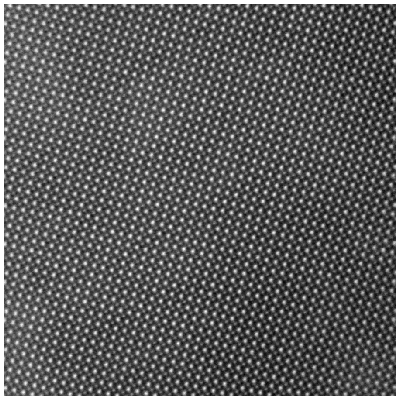

In [2]:
filename = 'data/FigS6_0716__Cryo_NSMO110_5-1Mx_0p5us_1024px_REGISTERED.tif'
image = imread(filename)
print(f'Image shape {image.shape}')
image = image[:min(image.shape),:min(image.shape)]
print(f'Cropped to {image.shape}')
image = kemstem.normalize(image)
print(f'Normalized to min: {image.min()}, max: {image.max()}')

fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(4,4))
ax.matshow(image,cmap='gray')
ax.axis('off')

(-0.5, 897.5, 897.5, -0.5)

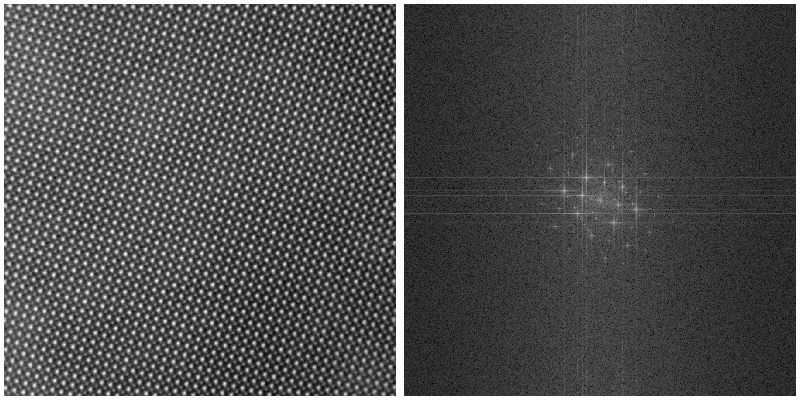

In [3]:
pattern_c = kemstem.prepare_fourier_pattern(image)
pattern_log = kemstem.prepare_fourier_pattern(image,log=True,log_offset=1e0) # Here we also take a log transform of the FFT for ease of visualization

fig,ax = plt.subplots(1,2,constrained_layout=True,figsize=(8,4))
ax[0].matshow(image,cmap='gray')
ax[0].axis('off')
ax[1].matshow(pattern_log,cmap='gray')
ax[1].axis('off')

# Identifying FFT peaks of interest to mask
The basic approach will be to generate a reference image without the periodic lattice distortions by masking out all the superlattice peaks, then mapping out the displacements between our measured column positions and this undistorted reference.

We begin by selecting the superlattice peaks to mask out. The next cell has the relevant peaks preselected, but to pick them manually change `preselected=preselected` to `preselected=None`.

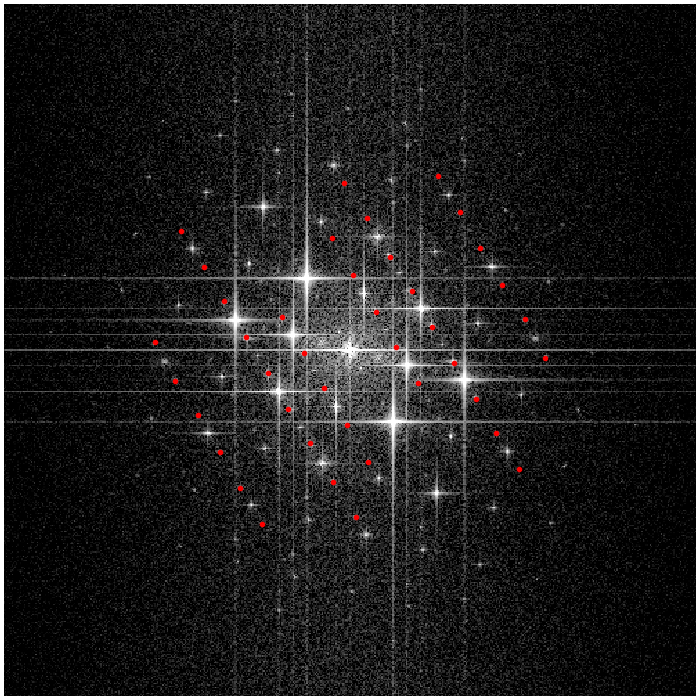

In [4]:
preselected = np.array([[443.43372957, 454.56627043, 471.48194938, 426.51805062, 495.77112942, 402.22887058, 522.95187851, 375.04812149,548.39768617, 349.60231383, 575.00012145, 322.99987855,363.33726683, 534.66273317, 389.3613883 , 508.6386117 ,413.65056834, 484.34943166, 439.67468981, 458.32531019,465.69881128, 432.30118872, 491.72293274, 406.27706726,516.59042659, 381.40957341, 544.34948949, 353.65051051,569.79529715, 328.20470285, 425.21684455, 472.78315545,451.24096602, 446.75903398, 476.68677367, 421.31322633,503.28920895, 394.71079105, 529.89164423, 368.10835577],
       [307.89143026, 590.10856974, 322.34927552, 575.65072448,339.12037602, 558.87962398, 354.7348489 , 543.2651511 ,369.77100797, 528.22899203, 385.38548085, 512.61451915,326.975786  , 571.024214  , 343.16857269, 554.83142731,358.20473176, 539.79526824, 373.81920465, 524.18079535,390.01199134, 507.98800866, 404.4698366 , 493.5301634 ,420.08430948, 477.91569052, 436.85540998, 461.14459002,453.04819667, 444.95180333, 399.84332611, 498.15667389,415.457799  , 482.542201  , 430.49395807, 467.50604193,446.68674476, 451.31325524, 462.30121764, 435.69878236]]).T
zoom = 250 # crop the pattern to display only the center area (with radius set by zoom in pixels) with useful information

# to select peaks by hand, change the preselected argument below to None
selected_peaks_PLD = kemstem.select_peaks(pattern_log,preselected=preselected,zoom=zoom,select_conjugates=True,figsize=(7,7),delete_within=5,vmin=3,vmax=7,)

# Fitting FFT peaks
Next, we fit the peaks using 2D gaussians. 2 parameters are important - the peak position, at which to center our masks, and the peak background, which we  set the masked areas to in order to match the surrounding background level. As peak width and amplitude are unimportant, we convolve a gaussian with the pattern to ease fitting.

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:00<00:00, 85.31it/s]


(199.0, 699.0, 699.0, 199.0)

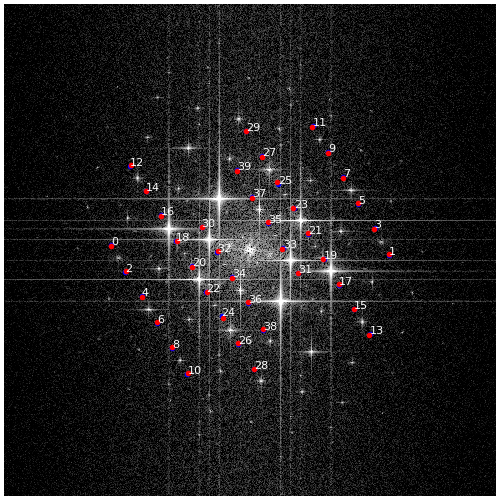

In [5]:
p0PLD = np.array(selected_peaks_PLD).T
# note - fitting to FFT amplitude without log transform - important because absolute background level is needed for this process
peaks_fit, perrors,popts,pdf = kemstem.refine_peaks_gf(gaussian_filter(np.abs(pattern_c),1.), p0PLD, window_dimension=9, remove_unfit = False)
pbackgrounds = popts[:,6]
fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(5,5))
kemstem.plot_numbered_points(pattern_log,p0PLD,ax=ax,color='b',zoom=zoom,vmin=3,vmax=7,) # original selected peak positions shown in blue
ax.plot(peaks_fit[:,1],peaks_fit[:,0],'r.') # fit positions shown in red
ax.axis('off')

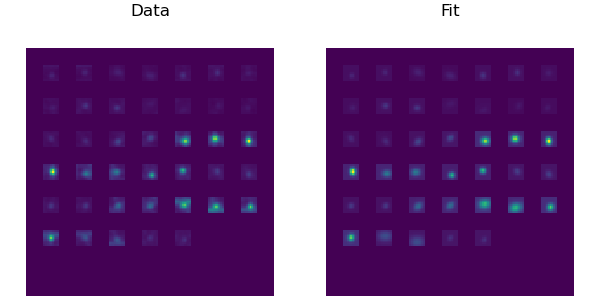

In [6]:
# plotting a comparison of the peaks in the filtered pattern and the fit results
# most important point is to check that the background levels are roughly similar
_ = kemstem.plot_fit_comparison(pdf) 

# Damping FFT peaks
Peaks are damped with circular masks. The mask size is an important parameter - it should be set to ensure that the superlattice peaks are entirely masked out, while minimizing the inclusion of any other features present in the pattern. The masked fourier pattern and its inverse fourier transform - the desired undistorted reference image - are shown below.

40it [00:00, 141.71it/s]


(-0.5, 897.5, 897.5, -0.5)

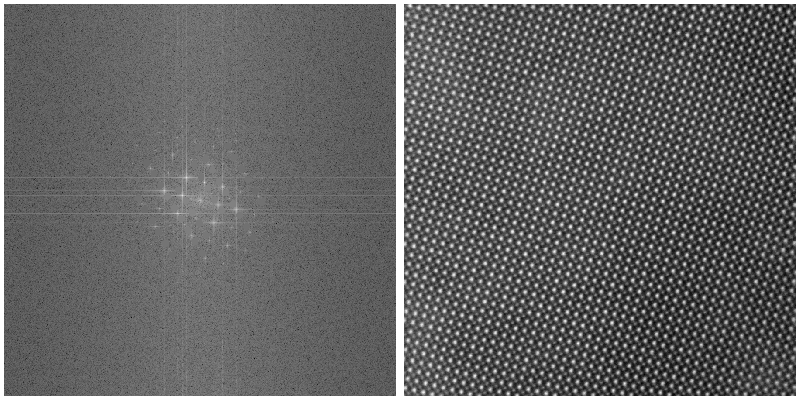

In [7]:
mask_size  = 8
damped_pattern_c,damped_image = kemstem.damp_peaks_circle(pattern_c,peaks_fit,pbackgrounds,mask_size)
fig,ax = plt.subplots(1,2,constrained_layout=True,figsize=(8,4))
ax[0].matshow(np.log(np.abs(damped_pattern_c)),cmap='gray')
ax[0].axis('off')
ax[1].matshow(damped_image,cmap='gray')
ax[1].axis('off')


# Visualizing intensity differences with the reference image
A quick and easy way to visualize contrast changes due to a PLD, or e.g. chemical ordering, is to simply plot the difference between the original (distorted) image and the (undistorted) reference generated by the Fourier masking performed above.

Greatest difference is 6.77% of image intensity, normalizing to a value of 1.0


(-0.5, 897.5, 897.5, -0.5)

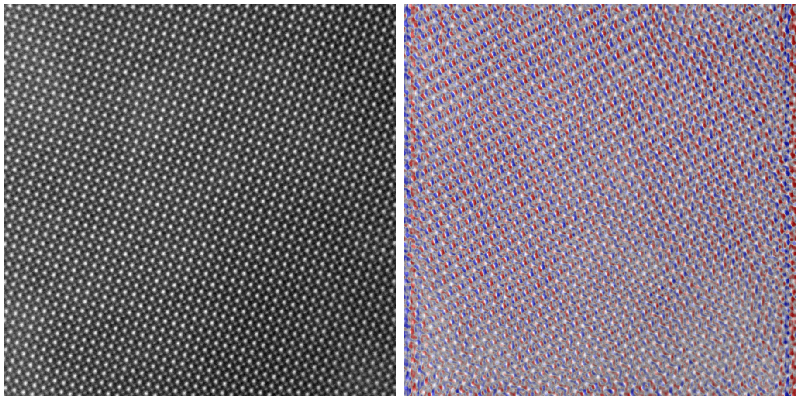

In [8]:
difference_image = damped_image - image
print(f'Greatest difference is {np.round(np.abs(difference_image).max()*100,2)}% of image intensity, normalizing to a value of 1.0')
difference_image = difference_image / np.abs(difference_image).max()
fig,ax = plt.subplots(1,2,constrained_layout=True,figsize=(8,4),sharex=True,sharey=True)
ax[0].matshow(image,cmap='gray')
ax[0].axis('off')
ax[1].matshow(image,cmap='gray')
ax[1].matshow(difference_image,cmap='bwr',alpha=.5,vmin=-.5,vmax=.5)
ax[1].axis('off')

# Fitting atomic columns
To measure the actual displacements of each atomic column in the image (the periodic lattice displacements) we'll need to identify the atomic columns and precicely fit their positions in the original and reference images.

We begin by finding the column positions using an approach derived from stemtool.

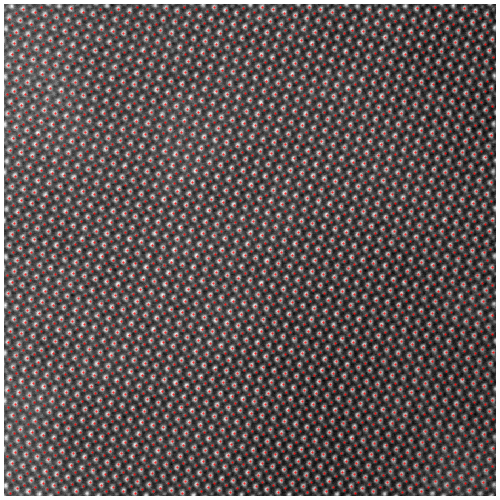

In [9]:
distance = 5
threshold = .1
c0 = kemstem.find_columns(image,distance=distance, threshold=threshold) # 8 .2

fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(5,5))
ax.matshow(image,cmap='gray')
ax.axis('off')
ax.plot(c0[:,1],c0[:,0],'r.',markersize=1)
print(f'{c0.shape[0]} columns found')

Next, we test fitting a single atomic column. The test column is selected with `test_it`, the key parameter is the fit window size, set with `window_dim`. It can be useful to preprocess the image to aid in fitting, though the precise approach will depend strongly on details of the image and precision considerations. Here we gaussian filter the image slightly to improve fit convergence, and wrap this preprocessing in a function to ensure precicely the same steps are taken with both the original and reference images to avoid any unwanted added differences between the two images.

The figure generated by this cell shows:
* The patch of image data being fit in the top left
* The fit result in the top right (should look as similar as possible to the top left)
* The full image in the bottom left, marked with the original and refined positions in blue and red.
* The fit residual, which should be as small and flat as possible.

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 103.00it/s]


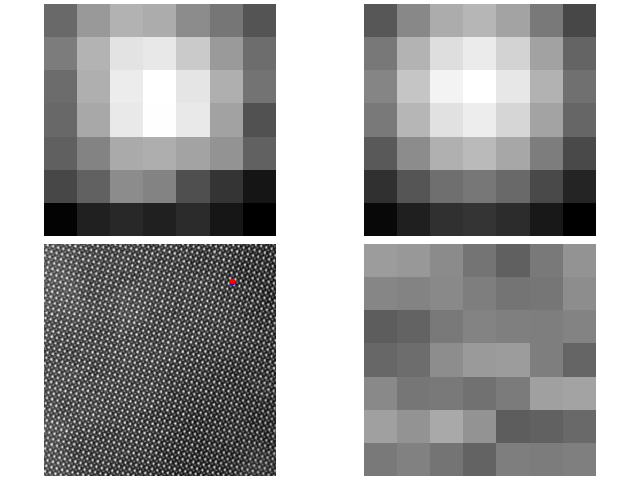

In [10]:
def preprocc_image(im):
    sigma = 0.5
    return gaussian_filter(im,sigma)

test_it = 3000
window_dim = 7
fitting_image = preprocc_image(image)
cf,errs,opts,data_fits = kemstem.refine_columns(fitting_image,c0[test_it,:],window_dim)

fig,ax = plt.subplots(2,2,constrained_layout=True)
ax[0,0].matshow(data_fits[:,:,0,0],cmap='gray')
ax[0,1].matshow(data_fits[:,:,0,1],cmap='gray')
ax[1,0].matshow(fitting_image,cmap='gray')
ax[1,0].plot(c0[test_it,1],c0[test_it,0],'b.') # original unfit position shown in blue
ax[1,0].plot(cf[0,1],cf[0,0],'r.') # fit position shown in red
ax[1,1].matshow(data_fits[:,:,0,0]-data_fits[:,:,0,1],cmap='gray',vmin=-.1,vmax=.1) # fit residual
_ = [tax.axis('off') for tax in ax.ravel()]

The following cell will now fit each column identified in the original image. This may take some time.

In [11]:
cf,errs,opts,data_fits = kemstem.refine_columns(fitting_image,c0,window_dim)

100%|████████████████████████████████████████████████████████████████████████████████████████████████| 3505/3505 [00:25<00:00, 135.22it/s]


(-0.5, 897.5, 897.5, -0.5)

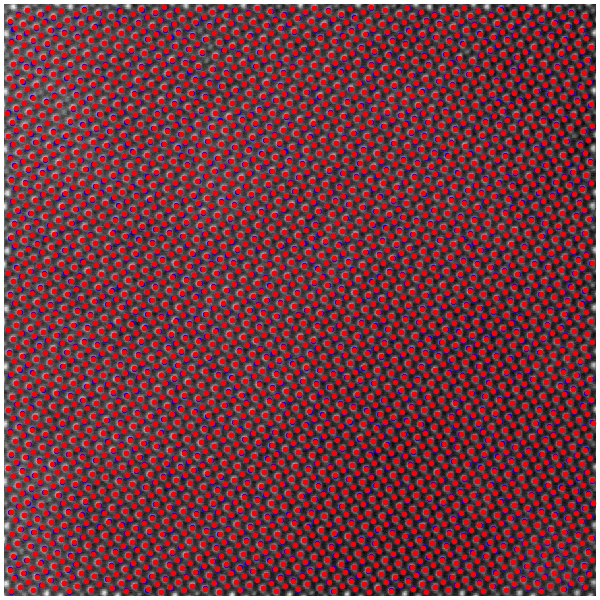

In [12]:
fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(6,6))
ax.matshow(image,cmap='gray')
ax.plot(c0[:,1],c0[:,0],'b.') # original positions shown in blue
ax.plot(cf[:,1],cf[:,0],'r.') # fit positions shown in red
ax.axis('off')

Next, we can fit each column in the masked reference image, using the same parameters and preprocessing

In [13]:
c_masked = kemstem.atomic.refine_columns(preprocc_image(damped_image),c0,window_dim)[0] # note - now fitting to damped image
# for initial guess positions, still using the columns identified in the original image
# this is reasonable here because the distortions are very small
# if this is not the case, the positions of the columns in the damped image should be
# identified with kemstem.find_columns

100%|████████████████████████████████████████████████████████████████████████████████████████████████| 3505/3505 [00:25<00:00, 138.17it/s]


# Mapping periodic lattice displacements
Finally, having found the positions of each atomic column in the original image which includes the periodic lattice displacements, and the masked reference image which excludes them, we can measure them by calculating the displacement vector between the positions in each image.

The displacements are visualized with arrows whose size (specifically, area) indicates the displacement magnitude, and whose orientation and color indicate the displacement direction. The triangles are scaled up significantly to make the picometer scale displacements easily visible.

(-0.5, 897.5, 897.5, -0.5)

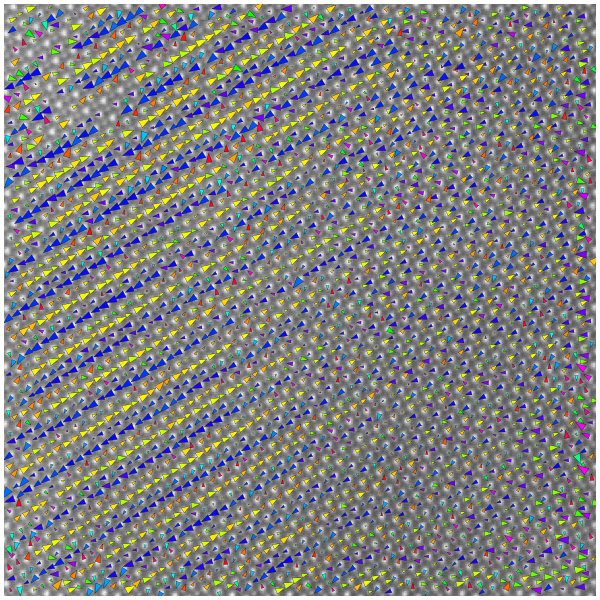

In [14]:
displacements = kemstem.measure_displacements(c_masked,cf,threshold=0.4)

cmap='hsv' # colormap for triangles
scale = 8e2 # scale factor for the triangles
shape = 3 # height vs width of triangles
colors = 'angle' # 'angle' or 'mag' - what color of triangles is set by
angleshift = np.pi/2 # shift applied to colormap
scalepower = 0.5 # power relating triangle size to displacement magnitude
linewidth = 0.2 # width of lines outlining triangles

fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(6,6))
ax.matshow(image,cmap='gray',alpha=.7)
kemstem.plot_displaced_site(cf,displacements,scale=scale,colors=colors,ax=ax,cmap=cmap,linewidth=linewidth,shape=shape,angleshift=angleshift,scale_power=scalepower)
ax.axis('off')

Finally, it's often useful to generate scale triangles to show how the arrows in the above visualization correspond to physical distances. The known image pixel size is used to convert from pixels to real space units. 

(-0.5, 897.5, 897.5, -0.5)

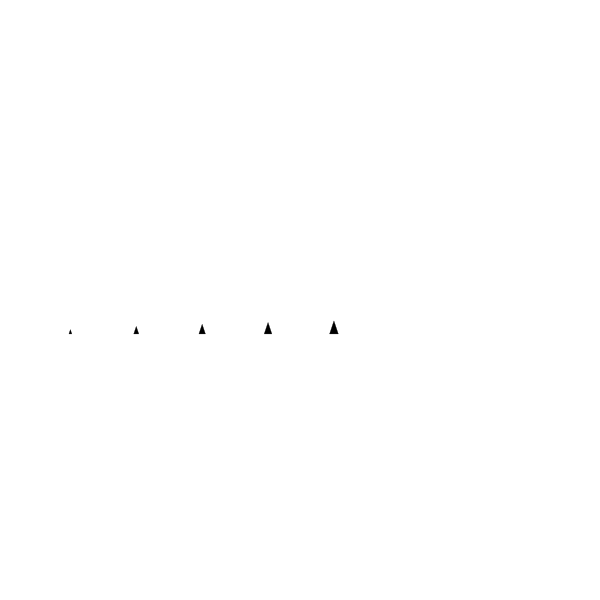

In [15]:
pm_per_px = 18.4 # size of a pixel in picometers
                 # find from image metadata or by calibrating with known structure
scale_pms = np.array([1,3,5,7,9]) # sizes of scale triangles in picometers


scale_posns_x = np.linspace(100,500,len(scale_pms)) # positioning triangles
scale_posns_y = 500* np.ones_like(scale_pms)

scale_c = np.stack((scale_posns_y,scale_posns_x),axis=1)
scale_disps = np.stack((-scale_pms,np.zeros_like(scale_pms)),axis=1) / pm_per_px

fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(6,6))
ax.matshow(np.zeros_like(image),cmap='gray',vmin=-1,vmax=0)
kemstem.plot_displaced_site(scale_c,scale_disps,scale=scale,colors=np.zeros_like(scale_pms),ax=ax,cmap='gray',linewidth=linewidth,shape=shape,angleshift=angleshift,scale_power=scalepower)
ax.axis('off')